
# Exploring Flood Insurance Claim Patterns and Severity

## Project Overview

This project examines historical flood insurance claims from FEMA's National Flood Insurance Program (NFIP). The goal is to determine whether information available early in the claim process can help identify claims that are likely to result in total payments of $50,000 or more.

The analysis includes exploratory data analysis, data preparation, model comparison, hyperparameter tuning, and evaluation on a held-out test period. The results are evaluated based on their potential usefulness for claims resource planning and prioritization.

**Data Source:** FEMA OpenFEMA - NFIP Redacted Claims (Version 3)

**Source URL:** https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3


In [1]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# Preprocessing
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier)

# Model tuning and evaluation
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score)

# Model interpretation
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## Initial Data Review

I started with a 5,000 record API pull to understand the structure of the NFIP claims data and identify variables that might be useful for the analysis.

In [2]:
url = "https://www.fema.gov/api/open/v3/NfipClaims"

params = {
    "$top": 5000,
    "$orderby": "id",
    "$format": "json"}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()
df = pd.DataFrame(data["NfipClaims"])

print("Dataset shape:", df.shape)

preview_cols = [
    "id",
    "yearOfLoss",
    "state",
    "dateOfLoss",
    "netBuildingPaymentAmount",
    "netContentsPaymentAmount",
    "netIccPaymentAmount"]

display(df[preview_cols].head())

Dataset shape: (5000, 84)


,id,yearOfLoss,state,dateOfLoss,netBuildingPaymentAmount,netContentsPaymentAmount,netIccPaymentAmount
0,5448672,2016,VA,2016-10-08T00:00:00.000Z,95649.74,21000.00,0.0
1,5448673,2017,TX,2017-08-27T00:00:00.000Z,22700.00,8300.00,0.0
2,5448674,2017,TX,2017-08-27T00:00:00.000Z,78568.82,3967.11,0.0
3,5448675,2005,LA,2005-08-29T00:00:00.000Z,8575.92,0.00,0.0
4,5448676,2004,FL,2004-09-16T00:00:00.000Z,5247.36,0.00,0.0


In [3]:
# Review the basic structure of the initial sample.
print("Rows:", len(df))
print("Columns:", df.shape[1])

print("\nData types:")
display(
    df.dtypes
    .value_counts()
    .rename("Count")
    .to_frame())

print("\nColumns with the most missing values:")
display(
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(10)
    .round(1)
    .rename("Missing %")
    .to_frame())

Rows: 5000
Columns: 84

Data types:


,Count
float64,38
object,29
bool,11
int64,6



Columns with the most missing values:


,Missing %
totalIccClaimPmtRecovery,98.9
mostRecentRecoveryDate,98.9
totalBldgClaimPmtRecovery,98.9
totalContentsClaimPmtRecovery,98.9
totalSubrogationRecovery,98.9
totalSalvageRecovery,98.9
floodCharacteristicsIndicator,98.3
eventDesignationNumber,92.6
interiorWaterDepth,85.5
exteriorWaterDepth,83.0


In [4]:

# Find columns related to claim payments
payment_cols = [
    col for col in df.columns
    if "payment" in col.lower()
    or "claim" in col.lower()
    or "amount" in col.lower()]

print("Potential payment variables:")
print(payment_cols)

Potential payment variables:
['amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim', 'buildingDamageAmount', 'netBuildingPaymentAmount', 'contentsDamageAmount', 'netContentsPaymentAmount', 'netIccPaymentAmount', 'nonPaymentReasonContents', 'nonPaymentReasonBuilding', 'mostRecentPaymentDate', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery']


In [5]:
# Review the available payment columns
display(df[payment_cols].describe().T)

# Check how many values are missing
display(df[payment_cols].isna().sum())

,count,mean,std,min,25%,50%,75%,max
amountPaidOnBuildingClaim,3999.0,35824.411675,78414.843561,0.00,2498.055,10402.67,41027.6850,1845885.26
amountPaidOnContentsClaim,3999.0,7372.117827,22397.516843,0.00,0.000,0.00,4990.5600,500000.00
amountPaidOnIncreasedCostOfComplianceClaim,3999.0,405.787042,3326.502889,0.00,0.000,0.00,0.0000,30000.00
buildingDamageAmount,3941.0,38948.995433,83064.510101,0.00,3690.000,12306.00,45000.0000,1938076.00
netBuildingPaymentAmount,5000.0,28618.534684,71561.984290,-0.15,0.000,5662.11,28402.9350,1845885.26
contentsDamageAmount,2121.0,17831.310702,38978.313897,0.00,1375.000,5513.00,19469.0000,997745.00
netContentsPaymentAmount,5000.0,5877.050128,20235.910401,0.00,0.000,0.00,2416.5725,500000.00
netIccPaymentAmount,5000.0,318.548476,2949.582236,0.00,0.000,0.00,0.0000,30000.00
totalBldgClaimPmtRecovery,56.0,3020.515536,12502.603831,0.00,0.000,0.00,220.4050,66613.00
totalContentsClaimPmtRecovery,56.0,1711.581250,4557.077978,0.00,0.000,0.00,2500.0000,32614.00


,0
amountPaidOnBuildingClaim,1001
amountPaidOnContentsClaim,1001
amountPaidOnIncreasedCostOfComplianceClaim,1001
buildingDamageAmount,1059
netBuildingPaymentAmount,0
contentsDamageAmount,2879
netContentsPaymentAmount,0
netIccPaymentAmount,0
nonPaymentReasonContents,3438
nonPaymentReasonBuilding,3906



## Initial Data Review

The initial dataset contains 5,000 flood insurance claim records and 84 variables. The data includes information about property characteristics, flood conditions, and claim payments.

Several variables have a large number of missing values, particularly those related to water depth, flood zones, and claim recoveries. These fields will need further review before deciding whether they should be included in the analysis.

The next step is to examine claim payments and identify an appropriate measure of claim severity.


In [6]:
# Calculate total net claim payments
df["totalClaimPayment"] = (
    df["netBuildingPaymentAmount"]
    + df["netContentsPaymentAmount"]
    + df["netIccPaymentAmount"])

# Review payment statistics
print("Total claim payment summary:")
display(df["totalClaimPayment"].describe())

# Check for zero and negative payments
print("Zero payments:",
      (df["totalClaimPayment"] == 0).sum())

print("Negative payments:",
      (df["totalClaimPayment"] < 0).sum())

print("Positive payments:",
      (df["totalClaimPayment"] > 0).sum())

Total claim payment summary:


,totalClaimPayment
count,5.000000e+03
mean,3.481413e+04
std,8.101729e+04
min,0.000000e+00
25%,4.912025e+02
50%,6.846950e+03
75%,3.434881e+04
max,1.845885e+06


Zero payments: 1094
Negative payments: 0
Positive payments: 3906


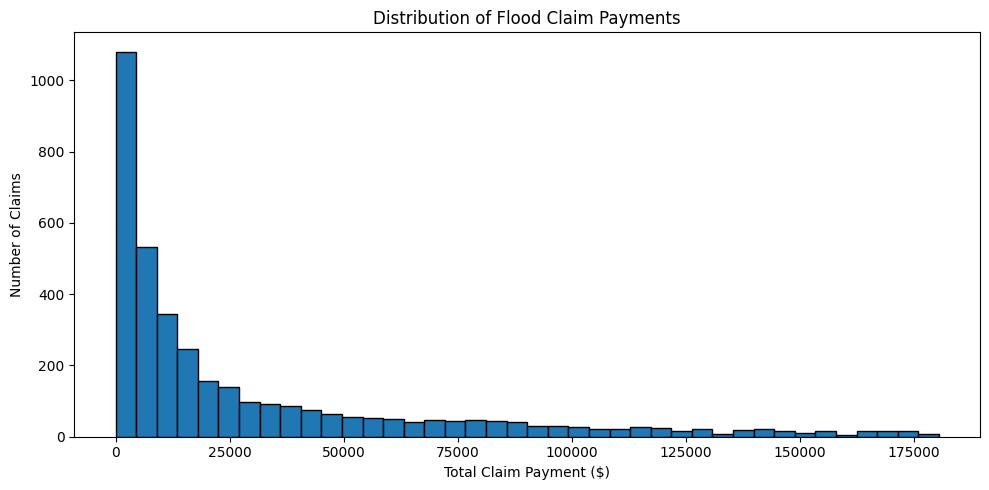

In [7]:
# Focus on positive claim payments
positive_payments = df.loc[
    df["totalClaimPayment"] > 0,
    "totalClaimPayment"]

# Limit the display to the 95th percentile
upper_limit = positive_payments.quantile(0.95)

plt.figure(figsize=(10, 5))

plt.hist(
    positive_payments,
    bins=40,
    range=(0, upper_limit),
    edgecolor="black")

plt.title("Distribution of Flood Claim Payments")
plt.xlabel("Total Claim Payment ($)")
plt.ylabel("Number of Claims")

plt.tight_layout()
plt.show()


### Claim Payment Distribution

The claim payments are heavily right-skewed, with most claims having relatively low payments and a smaller number involving much larger losses. The average payment is approximately 34,814 dollars, while the median is only 6,847 dollars. The largest payment in the sample is about 1.85 million dollars.

There are also 1,094 claims with no recorded net payment. These records will need to be considered when preparing the data for modeling.

The large difference between the average and median suggests that predicting exact claim amounts may be challenging. A classification model that identifies potentially high-cost claims may be a more practical approach.

To better visualize the distribution, I limited the histogram to the 95th percentile of positive claim payments. This makes the payment patterns easier to see without removing the larger claims from the dataset.


In [8]:
# Focus on claims with positive payments
paid_claims = df[df["totalClaimPayment"] > 0]

# Review payment percentiles
percentiles = paid_claims["totalClaimPayment"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

print("Payment percentiles for paid claims:")
display(percentiles)

# Review the number of high-cost claims
for threshold in [25000, 50000, 100000]:
    count = (paid_claims["totalClaimPayment"] >= threshold).sum()
    percentage = count / len(paid_claims) * 100

    print(f"Claims >= ${threshold:,}: {count} ({percentage:.1f}%)")

Payment percentiles for paid claims:


,totalClaimPayment
0.25,3700.8475
0.50,13470.5550
0.75,51138.2750
0.90,121397.2050
0.95,180543.7475
0.99,350000.0000


Claims >= $25,000: 1470 (37.6%)
Claims >= $50,000: 992 (25.4%)
Claims >= $100,000: 510 (13.1%)


In [9]:
# Check whether the current 5,000-record sample is concentrated
# in certain loss years or states.

year_summary = (
    df["yearOfLoss"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("Count")
    .to_frame())

year_summary["Percent"] = (
    year_summary["Count"] / len(df) * 100).round(1)

print("Claims by loss year:")
display(year_summary)

state_summary = (
    df["state"]
    .value_counts(dropna=False)
    .rename("Count")
    .to_frame())

state_summary["Percent"] = (
    state_summary["Count"] / len(df) * 100).round(1)

print("\nTop 15 states in the current sample:")
display(state_summary.head(15))

print(
    "\nNumber of states/territories represented:",
    df["state"].nunique(dropna=True))

Claims by loss year:


,Count,Percent
yearOfLoss,,
1978,78,1.6
1979,151,3.0
1980,94,1.9
1981,73,1.5
1982,71,1.4
1983,126,2.5
1984,59,1.2
1985,80,1.6
1986,39,0.8



Top 15 states in the current sample:


,Count,Percent
state,,
LA,867,17.3
FL,845,16.9
TX,770,15.4
NJ,350,7.0
NY,311,6.2
NC,209,4.2
PA,136,2.7
MS,127,2.5
IL,105,2.1



Number of states/territories represented: 54


### Initial Sample Check

The first 5,000 records cover a wide range of loss years and 54 states or territories, but the sample is concentrated in Louisiana, Florida, and Texas. Since the API request was ordered by ID, I am treating these records as an exploratory sample rather than assuming they represent the full NFIP claims population. Before modeling, I need a broader sample that is not dependent on record order.

In [10]:
# Review the API metadata for the current request.
print("Response sections:", data.keys())

print("\nAPI metadata:")
print(data.get("metadata", "No metadata returned"))

Response sections: dict_keys(['metadata', 'NfipClaims'])

API metadata:
{'skip': 0, 'select': None, 'rundate': '2026-10-19T01:06:40.242Z', 'top': 5000, 'filter': '', 'format': 'json', 'metadata': True, 'orderby': 'id ASC', 'entityname': 'NfipClaims', 'version': 'v3', 'url': '/api/open/v3/NfipClaims?%24top=5000&%24orderby=id&%24format=json', 'count': 0}


In [11]:
# Test API paging by pulling a second block of records.
test_params = {
    "$top": 5000,
    "$skip": 5000,
    "$orderby": "id",
    "$format": "json"}

test_response = requests.get(
    url,
    params=test_params,
    timeout=60)
test_response.raise_for_status()

test_data = test_response.json()
df_page2 = pd.DataFrame(test_data["NfipClaims"])

print("Second page shape:", df_page2.shape)

print("Overlap in IDs:",len(set(df["id"]) & set(df_page2["id"])))

Second page shape: (5000, 84)
Overlap in IDs: 0


In [12]:
# Check the OpenFEMA dataset metadata.
metadata_url = "https://www.fema.gov/api/open/v1/OpenFemaDataSets"

metadata_params = {
    "$filter": "name eq 'NfipClaims'",
    "$format": "json"}

metadata_response = requests.get(
    metadata_url,
    params=metadata_params,
    timeout=60)

metadata_response.raise_for_status()
metadata_data = metadata_response.json()

print("Response sections:", metadata_data.keys())

# Display the dataset metadata returned by FEMA.
metadata_records = metadata_data.get("OpenFemaDataSets", [])
metadata_df = pd.DataFrame(metadata_records)

print("Metadata records returned:", len(metadata_df))
display(metadata_df)

Response sections: dict_keys(['metadata', 'OpenFemaDataSets'])
Metadata records returned: 1


,identifier,name,title,description,webService,dataDictionary,keyword,modified,publisher,contactPoint,mbox,accessLevel,landingPage,temporal,api,version,bureauCode,programCode,accessLevelComment,license,spatial,theme,dataQuality,accrualPeriodicity,language,primaryITInvestmentUII,references,issued,systemOfRecords,recordCount,depDate,depApiMessage,depWebMessage,depNewURL,hash,lastRefresh,id,lastDataSetRefresh,distribution
0,openfema-95,NfipClaims,NFIP Redacted Claims,"Congress passed the National Flood Insurance Act (NFIA), Title 42 United States Code 4001 in 196...",https://www.fema.gov/api/open/v3/NfipClaims,https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3,"[NFIP, claims, flood insurance]",2026-07-20T00:00:00.000Z,FEMA/Resilience/Federal Insurance Directorate,OpenFEMA,openfema@fema.gov,public,https://www.fema.gov/flood-insurance,1970-08-31/,True,3,[024:70],[024:039],None,None,None,National Flood Insurance Program,true,R/P1M,en-US,None,[https://nfipservices.floodsmart.gov/manuals/jan_2015_consolidated_trrp.pdf],2019-06-01T00:00:00.000Z,None,2725989,None,None,None,None,9eaf194937eba43e6df9f1809f311d2c63058c81,2026-08-04T22:40:36.263Z,38707079-3400-4c56-bb50-3282881e21be,2026-09-09T16:23:10.614Z,"[{'format': 'csv', 'accessURL': 'https://www.fema.gov/about/reports-and-data/openfema/v3/NfipCla..."


In [13]:
# Check the metadata fields for record counts or full-data download links.
print("Metadata columns:")
print(metadata_df.columns.tolist())

relevant_fields = [
    col for col in metadata_df.columns
    if any(
        term in col.lower()
        for term in [
            "count",
            "record",
            "file",
            "download",
            "size",
            "url",
            "webservice",
            "dictionary",
            "landing"])]

print("\nPotentially useful metadata fields:")
display(metadata_df[relevant_fields].T)

Metadata columns:
['identifier', 'name', 'title', 'description', 'webService', 'dataDictionary', 'keyword', 'modified', 'publisher', 'contactPoint', 'mbox', 'accessLevel', 'landingPage', 'temporal', 'api', 'version', 'bureauCode', 'programCode', 'accessLevelComment', 'license', 'spatial', 'theme', 'dataQuality', 'accrualPeriodicity', 'language', 'primaryITInvestmentUII', 'references', 'issued', 'systemOfRecords', 'recordCount', 'depDate', 'depApiMessage', 'depWebMessage', 'depNewURL', 'hash', 'lastRefresh', 'id', 'lastDataSetRefresh', 'distribution']

Potentially useful metadata fields:


,0
webService,https://www.fema.gov/api/open/v3/NfipClaims
dataDictionary,https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3
landingPage,https://www.fema.gov/flood-insurance
systemOfRecords,None
recordCount,2725989
depNewURL,None


### Modeling Sample

The full NFIP claims dataset contains about 2.7 million records. Loading the entire dataset is not necessary for this project, so I created a reproducible 30,000 record sample spread across the full range of records.

Because the API returns records in ID order, I sampled small blocks from different sections of the dataset rather than using only the first records returned. I will check the year and geographic distributions again after creating the sample.

In [14]:
# Build a reproducible sample across the full NFIP dataset.
record_count = int(metadata_df.loc[0, "recordCount"])

sample_size = 30000
block_size = 500
n_blocks = sample_size // block_size

rng = np.random.default_rng(12345)

# Divide the full dataset into sections so the sample is spread
# across the entire ID ordered population.
segment_edges = np.linspace(
    0,
    record_count,
    n_blocks + 1,
    dtype=int)

sample_parts = []

for i in range(n_blocks):
    low = segment_edges[i]
    high = segment_edges[i + 1]

    # Randomly choose a starting point within each section.
    max_start = max(low, high - block_size)

    start = int(
        rng.integers(
            low,
            max_start + 1))

    sample_params = {
        "$top": block_size,
        "$skip": start,
        "$orderby": "id",
        "$format": "json"}

    sample_response = requests.get(
        url,
        params=sample_params,
        timeout=60)

    sample_response.raise_for_status()

    sample_data = sample_response.json()

    sample_parts.append(
        pd.DataFrame(sample_data["NfipClaims"]))

    if (i + 1) % 10 == 0:
        print(f"Blocks downloaded: {i + 1} of {n_blocks}")

sample_df = pd.concat(
    sample_parts,
    ignore_index=True)

# Remove duplicate IDs if any occurred.
sample_df = sample_df.drop_duplicates(
    subset="id").reset_index(drop=True)

print("\nFinal sample shape:", sample_df.shape)
print("Unique IDs:", sample_df["id"].nunique())

Blocks downloaded: 10 of 60
Blocks downloaded: 20 of 60
Blocks downloaded: 30 of 60
Blocks downloaded: 40 of 60
Blocks downloaded: 50 of 60
Blocks downloaded: 60 of 60

Final sample shape: (30000, 84)
Unique IDs: 30000


In [15]:
# Review the loss-year distribution in the broader sample.
sample_year_summary = (
    sample_df["yearOfLoss"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("Count")
    .to_frame())

sample_year_summary["Percent"] = (
    sample_year_summary["Count"] / len(sample_df) * 100
).round(1)

print("Loss-year range:")
print(
    sample_df["yearOfLoss"].min(),
    "to",
    sample_df["yearOfLoss"].max())

print("\nClaims by loss year:")
display(sample_year_summary)


# Review the geographic distribution.
sample_state_summary = (
    sample_df["state"]
    .value_counts(dropna=False)
    .rename("Count")
    .to_frame())

sample_state_summary["Percent"] = (
    sample_state_summary["Count"] / len(sample_df) * 100
).round(1)

print("\nTop 15 states in the broader sample:")
display(sample_state_summary.head(15))

print(
    "\nStates/territories represented:",
    sample_df["state"].nunique(dropna=True))

Loss-year range:
1978 to 2026

Claims by loss year:


,Count,Percent
yearOfLoss,,
1978,401,1.3
1979,932,3.1
1980,585,2.0
1981,359,1.2
1982,488,1.6
1983,802,2.7
1984,449,1.5
1985,552,1.8
1986,195,0.6



Top 15 states in the broader sample:


,Count,Percent
state,,
LA,5428,18.1
FL,4792,16.0
TX,4340,14.5
NJ,2224,7.4
NY,1905,6.4
NC,1222,4.1
PA,846,2.8
MS,704,2.3
CA,603,2.0



States/territories represented: 56


### Broader Sample Review

The 30,000 record sample includes claims from 56 states and territories. Louisiana, Florida, and Texas still account for almost half of the records, which is very similar to the concentration seen in the initial 5,000 record sample.

This suggests the geographic pattern was not caused only by using the first records returned by the API. I will use the broader 30,000 record sample for the remaining analysis while noting that it was created from blocks spread across the full dataset rather than as a simple random sample.

In [16]:
# Create total net claim payment in the broader sample.
sample_df["totalClaimPayment"] = (
    sample_df["netBuildingPaymentAmount"]
    + sample_df["netContentsPaymentAmount"]
    + sample_df["netIccPaymentAmount"])

# Review payment distribution.
paid_sample = sample_df.loc[
    sample_df["totalClaimPayment"] > 0,
    "totalClaimPayment"]

print("Sample size:", len(sample_df))
print("Zero payments:", (sample_df["totalClaimPayment"] == 0).sum())
print("Positive payments:", (sample_df["totalClaimPayment"] > 0).sum())

print("\nPositive-payment percentiles:")
display(
    paid_sample.quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nHigh-cost claim thresholds:")

for threshold in [25000, 50000, 100000]:
    count = (paid_sample >= threshold).sum()
    percent = count / len(paid_sample) * 100

    print(
        f"Claims >= ${threshold:,}: "
        f"{count} ({percent:.1f}% of positive claims)")

Sample size: 30000
Zero payments: 6862
Positive payments: 23138

Positive-payment percentiles:


,totalClaimPayment
0.25,3709.2650
0.50,13294.8700
0.75,50095.8550
0.90,117894.9810
0.95,177206.5625
0.99,340893.0739



High-cost claim thresholds:
Claims >= $25,000: 8701 (37.6% of positive claims)
Claims >= $50,000: 5830 (25.2% of positive claims)
Claims >= $100,000: 2986 (12.9% of positive claims)


### Claim Severity in the Broader Sample

The broader sample shows a very similar payment pattern to the initial 5,000 records. Among claims with a positive payment, the median is about 13,300 dollars and the 75th percentile is about 50,100 dollars.

About 25% of paid claims exceed 50,000 dollars, so  50,000 dollars remains a reasonable candidate for defining a high cost claim. Before setting the final target, I still need to understand the zero payment claims and make sure they represent completed claim outcomes rather than claims that have not fully developed.

In [17]:
# Review zero-payment claims before defining the modeling target.
zero_payment_claims = sample_df[
    sample_df["totalClaimPayment"] == 0].copy()

print("Zero-payment claims:", len(zero_payment_claims))
print("Percent of sample:",
    round(len(zero_payment_claims) / len(sample_df) * 100, 1))

print("\nZero-payment claims by loss year:")
display(
    zero_payment_claims["yearOfLoss"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame())

print("\nMost common building non-payment reasons:")
display(
    zero_payment_claims["nonPaymentReasonBuilding"]
    .value_counts(dropna=False)
    .head(15))

print("\nMost common contents non-payment reasons:")
display(
    zero_payment_claims["nonPaymentReasonContents"]
    .value_counts(dropna=False)
    .head(15))

Zero-payment claims: 6862
Percent of sample: 22.9

Zero-payment claims by loss year:


,Count
yearOfLoss,
1978,93
1979,188
1980,142
1981,103
1982,117
1983,203
1984,131
1985,137
1986,53



Most common building non-payment reasons:


,count
nonPaymentReasonBuilding,
01,1374
06,1323
97,1153
20,790
None,664
99,543
98,393
08,223
16,152



Most common contents non-payment reasons:


,count
nonPaymentReasonContents,
None,2444
20,947
97,918
06,911
99,527
01,427
98,344
08,129
16,104


### Zero-Payment Claims

Many zero payment claims have a recorded reason for why no payment was made, such as no demonstrable damage, no actual flood, or a loss below the deductible. Because these can represent legitimate claim outcomes, I will not remove zero payment claims automatically.

A few reason codes indicate possible data quality or claim development issues. I will review claims coded as error/delete, erroneous assignment, or loss in progress separately before defining the final modeling target.

In [18]:
# Flag zero payment claims that may need separate treatment.
review_codes = ["07", "98", "99"]

zero_payment_claims["building_reason"] = (
    zero_payment_claims["nonPaymentReasonBuilding"]
    .astype("string")
    .str.zfill(2))

zero_payment_claims["contents_reason"] = (
    zero_payment_claims["nonPaymentReasonContents"]
    .astype("string")
    .str.zfill(2))

needs_review = (
    zero_payment_claims["building_reason"].isin(review_codes)
    | zero_payment_claims["contents_reason"].isin(review_codes))

review_claims = zero_payment_claims.loc[needs_review].copy()

print("Zero-payment claims:", len(zero_payment_claims))
print("Claims with codes 07, 98, or 99:", len(review_claims))
print(
    "Percent of zero-payment claims needing review:",
    round(len(review_claims) / len(zero_payment_claims) * 100, 1))

print("\nReason combinations:")
display(
    review_claims[
        ["building_reason", "contents_reason"]]
    .value_counts(dropna=False)
    .head(15))

Zero-payment claims: 6862
Claims with codes 07, 98, or 99: 1192
Percent of zero-payment claims needing review: 17.4

Reason combinations:


,,count
building_reason,contents_reason,
99,99,353
98,98,274
99,<NA>,186
<NA>,99,170
98,<NA>,112
01,98,21
<NA>,98,12
97,98,12
07,07,11


In [19]:
# Separate likely data-quality issues from claims still in progress.
error_codes = ["98", "99"]
in_progress_code = "07"

error_flag = (
    zero_payment_claims["building_reason"].isin(error_codes)
    | zero_payment_claims["contents_reason"].isin(error_codes))

in_progress_flag = (
    (zero_payment_claims["building_reason"] == in_progress_code)
    | (zero_payment_claims["contents_reason"] == in_progress_code))

print("Zero-payment claims:", len(zero_payment_claims))

print(
    "Claims with error codes 98 or 99:",
    error_flag.sum())

print(
    "Claims with in-progress code 07:",
    in_progress_flag.sum())

print(
    "Claims with both an error code and code 07:",
    (error_flag & in_progress_flag).sum())

print(
    "\nPercent of full sample with error codes:",
    round(error_flag.sum() / len(sample_df) * 100, 1))

print(
    "Percent of full sample still in progress:",
    round(in_progress_flag.sum() / len(sample_df) * 100, 2))

Zero-payment claims: 6862
Claims with error codes 98 or 99: 1180
Claims with in-progress code 07: 12
Claims with both an error code and code 07: 0

Percent of full sample with error codes: 3.9
Percent of full sample still in progress: 0.04


In [20]:
print("\nLoss years for in-progress claims:")

display(
    zero_payment_claims.loc[
        in_progress_flag,
        "yearOfLoss"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame())


Loss years for in-progress claims:


,Count
yearOfLoss,
1983,1
1996,1
2011,8
2014,1
2019,1


### Payment Record Review

Most zero-payment claims appear to represent valid claim outcomes, but a small group has codes tied to administrative errors or unclear claim development. About 3.9% of the full sample has an error-related code (98 or 99), while only 12 records have code 07.

I will exclude these records from the modeling population because they do not provide a clean final claim-payment outcome. The remaining zero-payment claims will be kept as valid low-cost outcomes.

In [21]:
# Create normalized non-payment reason codes.
sample_df["building_reason"] = (
    sample_df["nonPaymentReasonBuilding"]
    .astype("string")
    .str.zfill(2))

sample_df["contents_reason"] = (
    sample_df["nonPaymentReasonContents"]
    .astype("string")
    .str.zfill(2))

# Exclude zero-payment records with error or unclear claim-development codes.
exclude_codes = ["07", "98", "99"]

exclude_flag = (
    (sample_df["totalClaimPayment"] == 0)
    & (
        sample_df["building_reason"].isin(exclude_codes)
        | sample_df["contents_reason"].isin(exclude_codes)))

model_df = (
    sample_df.loc[~exclude_flag]
    .copy()
    .reset_index(drop=True))

print("Original sample:", len(sample_df))
print("Records excluded:", exclude_flag.sum())
print("Modeling population:", len(model_df))

print(
    "High-cost claims >= $50,000:",
    (model_df["totalClaimPayment"] >= 50000).sum())

print(
    "High-cost claim rate:",
    round(
        (model_df["totalClaimPayment"] >= 50000).mean() * 100,1),"%")

Original sample: 30000
Records excluded: 1192
Modeling population: 28808
High-cost claims >= $50,000: 5830
High-cost claim rate: 20.2 %


### Modeling Population

After removing zero payment records with error or unclear claim development codes, 28,808 claims remain for modeling. The excluded records make up about 4% of the broader sample.

Using $50,000 as the current high cost threshold, about 20% of the remaining claims would be classified as high cost. I will keep this threshold as a candidate while reviewing the available predictors and checking for information that would not have been known early in the claim process.

In [22]:
# Review available fields before choosing predictors.
feature_review = pd.DataFrame({
    "Column": model_df.columns,
    "Data Type": model_df.dtypes.astype(str).values,
    "Missing": model_df.isna().sum().values})

feature_review["Missing %"] = (
    feature_review["Missing"] / len(model_df) * 100
).round(1)

feature_review = feature_review.sort_values(
    "Missing %",
    ascending=False
).reset_index(drop=True)

display(feature_review)

,Column,Data Type,Missing,Missing %
0,floodCharacteristicsIndicator,float64,28397,98.6
1,totalBldgClaimPmtRecovery,float64,28388,98.5
2,totalContentsClaimPmtRecovery,float64,28388,98.5
3,totalSalvageRecovery,float64,28388,98.5
4,mostRecentRecoveryDate,object,28388,98.5
...,...,...,...,...
82,openDate,object,0,0.0
83,preFirmIndicator,bool,0,0.0
84,foundationType,object,0,0.0
85,totalClaimPayment,float64,0,0.0


In [23]:
# Flag fields that are likely to reveal the final claim outcome.
leakage_terms = [
    "payment",
    "amountpaid",
    "damageamount",
    "recovery",
    "nonpaymentreason",
    "salvage",
    "mostrecentpayment"]

feature_review["Likely Leakage"] = feature_review["Column"].apply(
    lambda col: any(
        term in col.lower()
        for term in leakage_terms))

print("Likely leakage fields:")
display(
    feature_review.loc[
        feature_review["Likely Leakage"],
        ["Column", "Data Type", "Missing %"]
    ].sort_values("Column"))

print("\nRemaining fields for review:")
display(
    feature_review.loc[
        ~feature_review["Likely Leakage"],
        ["Column", "Data Type", "Missing %"]
    ].sort_values("Column"))

Likely leakage fields:


,Column,Data Type,Missing %
36,amountPaidOnBuildingClaim,float64,18.1
37,amountPaidOnContentsClaim,float64,18.1
39,amountPaidOnIncreasedCostOfComplianceClaim,float64,18.1
35,buildingDamageAmount,float64,19.2
24,contentsDamageAmount,float64,57.3
38,mostRecentPaymentDate,object,18.1
4,mostRecentRecoveryDate,object,98.5
70,netBuildingPaymentAmount,float64,0.0
73,netContentsPaymentAmount,float64,0.0
71,netIccPaymentAmount,float64,0.0



Remaining fields for review:


,Column,Data Type,Missing %
63,agricultureStructureIndicator,bool,0.0
59,asOfDate,object,0.0
16,baseFloodElevation,float64,76.1
22,basementEnclosureCrawlspaceType,float64,69.7
41,buildingDeductibleCode,object,10.0
...,...,...,...
77,stateOwnedIndicator,bool,0.0
66,totalBuildingInsuranceCoverage,int64,0.0
69,totalContentsInsuranceCoverage,float64,0.0
43,waterDepth,float64,8.0


In [24]:
# Show all remaining fields for predictor review.
remaining_review = (
    feature_review.loc[
        ~feature_review["Likely Leakage"],
        ["Column", "Data Type", "Missing %"]]
    .sort_values("Column")
    .reset_index(drop=True))

print(remaining_review.to_string(index=False))

                            Column Data Type  Missing %
     agricultureStructureIndicator      bool        0.0
                          asOfDate    object        0.0
                baseFloodElevation   float64       76.1
   basementEnclosureCrawlspaceType   float64       69.7
            buildingDeductibleCode    object       10.0
           buildingDescriptionCode   float64       64.1
             buildingPropertyValue   float64       19.3
           buildingReplacementCost   float64       19.3
                   building_reason    string       80.4
                     causeOfDamage    object        1.0
                       censusGeoid    object        5.4
       condominiumCoverageTypeCode    object        1.4
            contentsDeductibleCode    object       20.6
             contentsPropertyValue   float64       57.3
           contentsReplacementCost   float64       57.3
                   contents_reason    string       70.3
                        countyCode    object    

In [25]:
# Select predictors that could reasonably be available
# when a claim is opened or already exist on the policy.
candidate_features = [
    "agricultureStructureIndicator",
    "buildingDeductibleCode",
    "condominiumCoverageTypeCode",
    "contentsDeductibleCode",
    "countyCode",
    "dateOfLoss",
    "elevatedBuildingIndicator",
    "foundationType",
    "houseWorship",
    "locationOfContents",
    "nonProfitIndicator",
    "numberOfFloorsInTheInsuredBuilding",
    "numberOfUnits",
    "occupancyType",
    "openDate",
    "originalConstructionDate",
    "policyCount",
    "postFIRMConstructionIndicator",
    "preFirmIndicator",
    "primaryResidenceIndicator",
    "rateMethod",
    "ratedFloodZone",
    "rentalPropertyIndicator",
    "replacementCostBasis",
    "reportedZipCode",
    "smallBusinessIndicatorBuilding",
    "state",
    "stateOwnedIndicator",
    "totalBuildingInsuranceCoverage",
    "totalContentsInsuranceCoverage",
    "yearOfLoss"]

candidate_review = pd.DataFrame({
    "Column": candidate_features,
    "Data Type": [
        model_df[col].dtype
        for col in candidate_features],
    "Missing": [
        model_df[col].isna().sum()
        for col in candidate_features]})

candidate_review["Missing %"] = (
    candidate_review["Missing"]
    / len(model_df)
    * 100).round(1)

display(
    candidate_review.sort_values(
        "Missing %",
        ascending=False))

,Column,Data Type,Missing,Missing %
9,locationOfContents,float64,9831,34.1
3,contentsDeductibleCode,object,5925,20.6
1,buildingDeductibleCode,object,2872,10.0
23,replacementCostBasis,object,1830,6.4
21,ratedFloodZone,object,1482,5.1
4,countyCode,object,723,2.5
2,condominiumCoverageTypeCode,object,390,1.4
20,rateMethod,object,346,1.2
11,numberOfFloorsInTheInsuredBuilding,float64,175,0.6
15,originalConstructionDate,object,33,0.1


In [26]:
# Review the number of unique values in the candidate predictors.
cardinality_review = []

for col in candidate_features:
    cardinality_review.append({
        "Column": col,
        "Data Type": str(model_df[col].dtype),
        "Unique Values": model_df[col].nunique(dropna=True),
        "Missing %": round(
            model_df[col].isna().mean() * 100,1)})

cardinality_review = pd.DataFrame(
    cardinality_review
).sort_values(
    "Unique Values",
    ascending=False
).reset_index(drop=True)

display(cardinality_review)

,Column,Data Type,Unique Values,Missing %
0,openDate,object,7253,0.0
1,reportedZipCode,object,6141,0.0
2,dateOfLoss,object,5190,0.0
3,originalConstructionDate,object,4530,0.1
4,totalBuildingInsuranceCoverage,int64,2430,0.0
5,countyCode,object,1580,2.5
6,totalContentsInsuranceCoverage,float64,976,0.0
7,numberOfUnits,float64,90,0.1
8,policyCount,int64,78,0.0
9,ratedFloodZone,object,61,5.1


In [27]:
# Convert important date fields to datetime.
model_df["dateOfLoss_dt"] = pd.to_datetime(
    model_df["dateOfLoss"],
    errors="coerce")

model_df["openDate_dt"] = pd.to_datetime(
    model_df["openDate"],
    errors="coerce")

model_df["constructionDate_dt"] = pd.to_datetime(
    model_df["originalConstructionDate"],
    errors="coerce")

# Create claim reporting lag.
model_df["reportingLagDays"] = (
    model_df["openDate_dt"]
    - model_df["dateOfLoss_dt"]).dt.days

# Estimate building age at the time of loss.
model_df["buildingAgeAtLoss"] = (
    model_df["dateOfLoss_dt"].dt.year
    - model_df["constructionDate_dt"].dt.year)

# Capture seasonal timing of the loss.
model_df["lossMonth"] = (
    model_df["dateOfLoss_dt"].dt.month)

model_df["lossQuarter"] = (
    model_df["dateOfLoss_dt"].dt.quarter)

# Review the new features.
derived_features = [
    "reportingLagDays",
    "buildingAgeAtLoss",
    "lossMonth",
    "lossQuarter"]

display(model_df[derived_features]
    .describe()
    .T)

,count,mean,std,min,25%,50%,75%,max
reportingLagDays,28808.0,24.777666,61.422129,-30.0,3.0,9.0,24.0,2723.0
buildingAgeAtLoss,25179.0,36.311490,22.752070,-22.0,19.0,33.0,50.0,161.0
lossMonth,28808.0,7.332304,2.742396,1.0,5.0,8.0,9.0,12.0
lossQuarter,28808.0,2.757186,0.908424,1.0,2.0,3.0,3.0,4.0


In [28]:
# Review unusual values in the derived features.
print(
    "Negative reporting lag:",
    (model_df["reportingLagDays"] < 0).sum())

print(
    "Reporting lag over 365 days:",
    (model_df["reportingLagDays"] > 365).sum())

print(
    "Negative building age:",
    (model_df["buildingAgeAtLoss"] < 0).sum())

print(
    "Building age over 120 years:",
    (model_df["buildingAgeAtLoss"] > 120).sum())

print(
    "Missing building age:",
    model_df["buildingAgeAtLoss"].isna().sum())

print("\nReporting lag percentiles:")
display(
    model_df["reportingLagDays"].quantile(
        [0.01, 0.05, 0.50, 0.95, 0.99, 1.00]))

print("\nBuilding age percentiles:")
display(
    model_df["buildingAgeAtLoss"].quantile(
        [0.01, 0.05, 0.50, 0.95, 0.99, 1.00]))

Negative reporting lag: 40
Reporting lag over 365 days: 130
Negative building age: 127
Building age over 120 years: 24
Missing building age: 3629

Reporting lag percentiles:


,reportingLagDays
0.01,0.00
0.05,0.00
0.50,9.00
0.95,94.00
0.99,241.93
1.00,2723.00



Building age percentiles:


,buildingAgeAtLoss
0.01,0.0
0.05,5.0
0.50,33.0
0.95,80.0
0.99,104.0
1.00,161.0


### Derived Feature Review

A small number of records produced negative reporting lags or negative building ages, which are not logically valid. I treated those values as missing rather than removing the entire claim.

The very long reporting lags and older building ages were uncommon but still possible, so I kept them for now rather than applying an arbitrary cutoff.

In [29]:
# Clean clearly invalid derived values without dropping the claims.
model_df["reportingLagDays_clean"] = (
    model_df["reportingLagDays"]
    .mask(model_df["reportingLagDays"] < 0))

model_df["buildingAgeAtLoss_clean"] = (
    model_df["buildingAgeAtLoss"]
    .mask(model_df["buildingAgeAtLoss"] < 0))

print(
    "Missing reporting lag after cleaning:",
    model_df["reportingLagDays_clean"].isna().sum())

print(
    "Missing building age after cleaning:",
    model_df["buildingAgeAtLoss_clean"].isna().sum())

display(model_df[["reportingLagDays_clean",
            "buildingAgeAtLoss_clean",
            "lossMonth",
            "lossQuarter"]]
    .describe()
    .T)

Missing reporting lag after cleaning: 40
Missing building age after cleaning: 3756


,count,mean,std,min,25%,50%,75%,max
reportingLagDays_clean,28768.0,24.827656,61.449409,0.0,3.00,9.0,25.0,2723.0
buildingAgeAtLoss_clean,25052.0,36.512175,22.632572,0.0,19.75,34.0,50.0,161.0
lossMonth,28808.0,7.332304,2.742396,1.0,5.00,8.0,9.0,12.0
lossQuarter,28808.0,2.757186,0.908424,1.0,2.00,3.0,3.0,4.0


,yearOfLoss,Claims,HighCostClaims,HighCostRate (%),MedianPayment
0,1978,401,0,0.0,955.0
1,1979,920,8,0.9,1606.0
2,1980,565,3,0.5,1653.0
3,1981,351,1,0.3,901.0
4,1982,476,5,1.1,1597.0
5,1983,777,12,1.5,1854.0
6,1984,440,4,0.9,2234.0
7,1985,543,9,1.7,2310.0
8,1986,193,1,0.5,2186.0
9,1987,191,0,0.0,1156.0


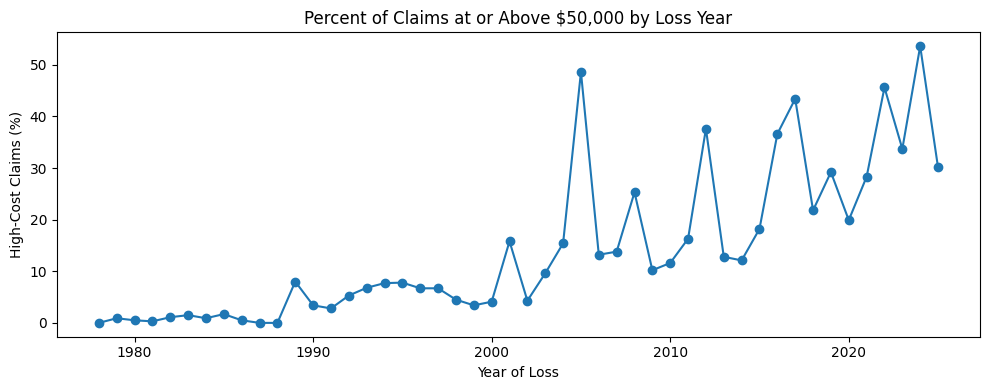

In [30]:
# Check whether the $50,000 threshold behaves consistently over time.
model_df["highCostCandidate"] = (
    model_df["totalClaimPayment"] >= 50000).astype(int)

year_target_review = (
    model_df.groupby("yearOfLoss")
    .agg(Claims=("highCostCandidate", "size"),
        HighCostClaims=("highCostCandidate", "sum"),
        HighCostRate=("highCostCandidate", "mean"),
        MedianPayment=("totalClaimPayment", "median")).reset_index())

year_target_review["HighCostRate (%)"] = (
    year_target_review["HighCostRate"] * 100).round(1)

year_target_review["MedianPayment"] = (
    year_target_review["MedianPayment"]
    .round(0))

display(year_target_review[
        ["yearOfLoss",
            "Claims",
            "HighCostClaims",
            "HighCostRate (%)",
            "MedianPayment"]])

# Plot years with enough observations to make the rate more stable.
stable_years = year_target_review[
    year_target_review["Claims"] >= 100]

plt.figure(figsize=(10, 4))

plt.plot(
    stable_years["yearOfLoss"],
    stable_years["HighCostRate (%)"],
    marker="o")

plt.title("Percent of Claims at or Above $50,000 by Loss Year")
plt.xlabel("Year of Loss")
plt.ylabel("High-Cost Claims (%)")

plt.tight_layout()
plt.show()

### Time Period for Modeling

The 50,000 dollar threshold is not consistent across the full historical period. Claims from earlier decades rarely exceeded this amount, while the percentage of claims above 50,000 dollar is much higher in recent years.

To make the target more relevant to current claim severity, I limited the modeling period to 2010 through 2024. This also avoids relying on the most recent 2025 through 2026 claims, which may be less fully developed.

In [31]:
# Limit the modeling population to recent, more comparable claim years.
recent_df = (
    model_df.loc[
        model_df["yearOfLoss"].between(2010, 2024)]
    .copy()
    .reset_index(drop=True))

# Create the candidate high-cost target.
recent_df["highCostClaim"] = (
    recent_df["totalClaimPayment"] >= 50000).astype(int)

print("Recent modeling population:", len(recent_df))

print("High-cost claims:",
    recent_df["highCostClaim"].sum())

print("High-cost claim rate:",
    round(recent_df["highCostClaim"].mean() * 100,1),"%")

print("Loss-year range:",
    recent_df["yearOfLoss"].min(),
    "to",
    recent_df["yearOfLoss"].max())

Recent modeling population: 10040
High-cost claims: 3337
High-cost claim rate: 33.2 %
Loss-year range: 2010 to 2024


### Modeling Definition

For the predictive analysis, I limited the data to claims from 2010 through 2024 and defined a high-cost claim as a total payment of $50,000 or more. This leaves 10,040 claims, with about 33% classified as high cost.

The predictor set is limited to information that could reasonably be available when a claim is opened or already exists on the policy. Payment, damage, recovery, and other outcome-related fields are excluded to avoid data leakage.

In [32]:
# Final predictor set for the early claim severity model.
numeric_features = [
    "totalBuildingInsuranceCoverage",
    "totalContentsInsuranceCoverage",
    "numberOfFloorsInTheInsuredBuilding",
    "numberOfUnits",
    "policyCount",
    "reportingLagDays_clean",
    "buildingAgeAtLoss_clean",
    "lossMonth",
    "yearOfLoss"]

categorical_features = [
    "state",
    "ratedFloodZone",
    "occupancyType",
    "foundationType",
    "buildingDeductibleCode",
    "contentsDeductibleCode",
    "condominiumCoverageTypeCode",
    "locationOfContents",
    "rateMethod",
    "replacementCostBasis",
    "agricultureStructureIndicator",
    "elevatedBuildingIndicator",
    "houseWorship",
    "nonProfitIndicator",
    "postFIRMConstructionIndicator",
    "preFirmIndicator",
    "primaryResidenceIndicator",
    "rentalPropertyIndicator",
    "smallBusinessIndicatorBuilding",
    "stateOwnedIndicator"]

final_features = numeric_features + categorical_features

X = recent_df[final_features].copy()
y = recent_df["highCostClaim"].copy()

print("Modeling rows:", len(X))
print("Predictors:", len(final_features))
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(1))

print("\nPredictors with the most missing values:")
display(
    X.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(10)
    .round(1))

Modeling rows: 10040
Predictors: 29
Numeric predictors: 9
Categorical predictors: 20

Target distribution:
highCostClaim
0    6703
1    3337
Name: count, dtype: int64

Target percentages:
highCostClaim
0    66.8
1    33.2
Name: proportion, dtype: float64

Predictors with the most missing values:


,0
locationOfContents,36.1
contentsDeductibleCode,21.2
buildingDeductibleCode,1.6
buildingAgeAtLoss_clean,1.3
replacementCostBasis,0.5
numberOfFloorsInTheInsuredBuilding,0.5
ratedFloodZone,0.5
numberOfUnits,0.3
condominiumCoverageTypeCode,0.1
reportingLagDays_clean,0.0


### Train, Validation, and Test Split

Because the goal is to identify high-cost claims in future periods, I used a chronological split rather than randomly mixing claims from different years. Claims from 2010 through 2020 are used for training, 2021 through 2022 for validation, and 2023 through 2024 are held out for the final test.

In [33]:
# Split the data chronologically so newer claims are not used
# to predict older claims.
train_mask = recent_df["yearOfLoss"] <= 2020

valid_mask = recent_df["yearOfLoss"].between(2021,2022)

test_mask = recent_df["yearOfLoss"].between(2023,2024)

X_train = recent_df.loc[
    train_mask,
    final_features].copy()

y_train = recent_df.loc[
    train_mask,
    "highCostClaim"].copy()

X_valid = recent_df.loc[
    valid_mask,
    final_features].copy()

y_valid = recent_df.loc[
    valid_mask,
    "highCostClaim"].copy()

X_test = recent_df.loc[
    test_mask,
    final_features].copy()

y_test = recent_df.loc[
    test_mask,
    "highCostClaim"].copy()

# Review the split sizes and target rates.
split_summary = pd.DataFrame({
    "Split": [
        "Training",
        "Validation",
        "Test"],
    "Rows": [
        len(X_train),
        len(X_valid),
        len(X_test)],
    "High-Cost Claims": [
        y_train.sum(),
        y_valid.sum(),
        y_test.sum()],
    "High-Cost Rate (%)": [
        y_train.mean() * 100,
        y_valid.mean() * 100,
        y_test.mean() * 100]})

split_summary["High-Cost Rate (%)"] = (
    split_summary["High-Cost Rate (%)"]
    .round(1))

display(split_summary)

,Split,Rows,High-Cost Claims,High-Cost Rate (%)
0,Training,7749,2311,29.8
1,Validation,1018,383,37.6
2,Test,1273,643,50.5


### Split Review

The percentage of high-cost claims increases from 29.8% in the training period to 37.6% in validation and 50.5% in the test period. I kept the chronological split because it better represents how the model would be used on future claims.

Because the class balance changes over time, accuracy alone will not be a good measure of performance. I will compare the models using precision, recall, F1, ROC-AUC, and PR-AUC, with threshold decisions made on the validation set.

In [34]:
# Import preprocessing tools.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric variables: fill missing values with the median and standardize.
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())])

# Categorical variables: fill missing values and create indicator columns.
categorical_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="most_frequent")),(
            "onehot",OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(
    transformers=[("numeric",
            numeric_transformer,
            numeric_features),
        ("categorical",
            categorical_transformer,
            categorical_features)])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


### Baseline and Initial Model

I first compared a simple majority-class baseline with logistic regression. The baseline shows what we would get without learning any useful claim patterns, while logistic regression provides a straightforward first model for identifying high-cost claims.

In [35]:
# Import models and evaluation metrics.
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score)

# Build the baseline model.
dummy_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model",DummyClassifier(strategy="most_frequent"))])

# Build the first predictive model.
logistic_model = Pipeline(
    steps=[("preprocessor", clone(preprocessor)),
        ("model",LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=12345))])

models = {"Dummy Baseline": dummy_model,
    "Logistic Regression": logistic_model}

validation_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)
    prob = model.predict_proba(X_valid)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(
            y_valid,
            pred,
            zero_division=0),
        "Recall": recall_score(
            y_valid,
            pred,
            zero_division=0),
        "F1": f1_score(
            y_valid,
            pred,
            zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_valid,
            prob),
        "PR-AUC": average_precision_score(
            y_valid,
            prob)})

validation_results = pd.DataFrame(validation_results)

display(validation_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy Baseline,0.624,0.000,0.00,0.000,0.500,0.376
1,Logistic Regression,0.604,0.482,0.71,0.574,0.654,0.478


### Initial Model Results

The dummy baseline reached 62.4% accuracy by predicting every claim as not high cost, but it failed to identify any high-cost claims. This shows why accuracy alone is not useful for this problem.

Logistic regression identified about 71% of the high-cost claims, although only about 48% of the claims it flagged were actually high cost. Its F1, ROC-AUC, and PR-AUC were all better than the baseline, so the available claim and policy information appears to contain useful predictive signal.

In [36]:
# Compare tree-based models with the initial logistic regression.
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

tree_models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=12345),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=12345,
        n_jobs=-1)}

new_results = []

for name, classifier in tree_models.items():

    model = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", classifier)])

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)
    prob = model.predict_proba(X_valid)[:, 1]

    models[name] = model

    new_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(
            y_valid,
            pred,
            zero_division=0),
        "Recall": recall_score(
            y_valid,
            pred,
            zero_division=0),
        "F1": f1_score(
            y_valid,
            pred,
            zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_valid,
            prob),
        "PR-AUC": average_precision_score(
            y_valid,
            prob)})

validation_results = pd.concat(
    [validation_results,
      pd.DataFrame(new_results)],
    ignore_index=True)

display(validation_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy Baseline,0.624,0.000,0.000,0.000,0.500,0.376
1,Logistic Regression,0.604,0.482,0.710,0.574,0.654,0.478
2,Decision Tree,0.577,0.462,0.765,0.576,0.638,0.465
3,Random Forest,0.646,0.689,0.110,0.189,0.733,0.584


### Model Comparison

The models show different tradeoffs. The decision tree identifies the largest share of high-cost claims at the default cutoff, while the random forest has the strongest ROC-AUC and PR-AUC but very low recall.

This suggests that the random forest may be ranking claim severity well even though the standard 0.50 probability cutoff is too restrictive. I will compare one additional ensemble model before tuning the decision threshold.

In [37]:
# Add gradient boosting to the initial model comparison.
from sklearn.ensemble import GradientBoostingClassifier

gradient_model = Pipeline(
    steps=[("preprocessor", clone(preprocessor)),
        ("model",GradientBoostingClassifier(random_state=12345))])

gradient_model.fit(X_train, y_train)

gradient_pred = gradient_model.predict(X_valid)
gradient_prob = gradient_model.predict_proba(X_valid)[:, 1]

models["Gradient Boosting"] = gradient_model

gradient_result = pd.DataFrame([
    {
        "Model": "Gradient Boosting",
        "Accuracy": accuracy_score(y_valid, gradient_pred),
        "Precision": precision_score(
            y_valid,
            gradient_pred,
            zero_division=0),
        "Recall": recall_score(
            y_valid,
            gradient_pred,
            zero_division=0),
        "F1": f1_score(
            y_valid,
            gradient_pred,
            zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_valid,
            gradient_prob),
        "PR-AUC": average_precision_score(
            y_valid,
            gradient_prob)}])

validation_results = pd.concat(
    [validation_results,gradient_result],
    ignore_index=True)

display(validation_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy Baseline,0.624,0.000,0.000,0.000,0.500,0.376
1,Logistic Regression,0.604,0.482,0.710,0.574,0.654,0.478
2,Decision Tree,0.577,0.462,0.765,0.576,0.638,0.465
3,Random Forest,0.646,0.689,0.110,0.189,0.733,0.584
4,Gradient Boosting,0.643,0.672,0.102,0.177,0.702,0.557


### Initial Model Comparison

Random forest produced the strongest ROC-AUC and PR-AUC, suggesting that it does the best job ranking higher-risk claims above lower-risk claims. However, at the default 0.50 cutoff it identifies only 11% of the high-cost claims.

Gradient boosting showed a similar pattern. Before choosing a final model, I need to look at lower probability cutoffs and consider the tradeoff between catching more high-cost claims and creating more false positives.

In [38]:
# Compare decision thresholds for the two strongest ranking models.
thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50]

threshold_results = []

for model_name in [
    "Random Forest",
    "Gradient Boosting"]:

    model = models[model_name]

    valid_prob = model.predict_proba(X_valid)[:, 1]

    for threshold in thresholds:

        valid_pred = (valid_prob >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Claims Flagged": valid_pred.sum(),
            "High-Cost Caught": (
                (valid_pred == 1)
                & (y_valid == 1)).sum(),
            "Precision": precision_score(
                y_valid,
                valid_pred,
                zero_division=0),
            "Recall": recall_score(
                y_valid,
                valid_pred,
                zero_division=0),
            "F1": f1_score(
                y_valid,
                valid_pred,
                zero_division=0)})

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(3))

,Model,Threshold,Claims Flagged,High-Cost Caught,Precision,Recall,F1
0,Random Forest,0.10,926,376,0.406,0.982,0.574
1,Random Forest,0.15,778,355,0.456,0.927,0.612
2,Random Forest,0.20,612,313,0.511,0.817,0.629
3,Random Forest,0.25,475,264,0.556,0.689,0.615
4,Random Forest,0.30,345,209,0.606,0.546,0.574
5,Random Forest,0.35,224,134,0.598,0.350,0.442
6,Random Forest,0.40,154,95,0.617,0.248,0.354
7,Random Forest,0.45,98,63,0.643,0.164,0.262
8,Random Forest,0.50,63,44,0.698,0.115,0.197
9,Gradient Boosting,0.10,868,370,0.426,0.966,0.592


### Threshold Review

Lowering the probability cutoff substantially improved the random forest's ability to identify high-cost claims. A 0.20 cutoff produced the highest F1 score and caught about 82% of high-cost claims, but it also flagged about 60% of the validation claims.

The 0.25 to 0.30 range creates a smaller review group but also misses more severe claims. I will tune the random forest first and then revisit the cutoff using the improved model.

In [39]:
# Tune the random forest using chronological cross-validation.
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Sort the training claims by loss date before time-based cross-validation.
train_order = (
    recent_df.loc[train_mask, "dateOfLoss_dt"]
    .sort_values()
    .index)

X_train_tune = recent_df.loc[
    train_order,
    final_features].copy()

y_train_tune = recent_df.loc[
    train_order,
    "highCostClaim"].copy()

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1))])

param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [1, 5, 10]}

time_cv = TimeSeriesSplit(n_splits=4)

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=time_cv,
    n_jobs=-1)

rf_grid.fit(
    X_train_tune,
    y_train_tune)

print("Best parameters:")
print(rf_grid.best_params_)

print("\nBest cross-validation PR-AUC:",
    round(rf_grid.best_score_, 3))

Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}

Best cross-validation PR-AUC: 0.57


In [40]:
# Evaluate the tuned random forest on the validation period.
tuned_rf = rf_grid.best_estimator_

tuned_prob = tuned_rf.predict_proba(X_valid)[:, 1]
tuned_pred = tuned_rf.predict(X_valid)

print("Tuned random forest validation results:")

print("ROC-AUC:",round(roc_auc_score(y_valid, tuned_prob), 3))

print("PR-AUC:",round(average_precision_score(y_valid, tuned_prob), 3))

print("F1 at 0.50:",round(f1_score(y_valid, tuned_pred), 3))

# Review several probability cutoffs.
tuned_threshold_results = []

for threshold in thresholds:
    pred = (tuned_prob >= threshold).astype(int)

    tuned_threshold_results.append({
        "Threshold": threshold,
        "Claims Flagged": pred.sum(),
        "High-Cost Caught": (
            (pred == 1) & (y_valid == 1)).sum(),
        "Precision": precision_score(
            y_valid,
            pred,
            zero_division=0),
        "Recall": recall_score(
            y_valid,
            pred,
            zero_division=0),
        "F1": f1_score(
            y_valid,
            pred,
            zero_division=0)})

tuned_threshold_results = pd.DataFrame(tuned_threshold_results)

display(tuned_threshold_results.round(3))

Tuned random forest validation results:
ROC-AUC: 0.743
PR-AUC: 0.599
F1 at 0.50: 0.599


,Threshold,Claims Flagged,High-Cost Caught,Precision,Recall,F1
0,0.10,1018,383,0.376,1.000,0.547
1,0.15,1013,383,0.378,1.000,0.549
2,0.20,988,381,0.386,0.995,0.556
3,0.25,941,376,0.400,0.982,0.568
4,0.30,862,366,0.425,0.956,0.588
5,0.35,748,348,0.465,0.909,0.615
6,0.40,588,304,0.517,0.794,0.626
7,0.45,461,260,0.564,0.679,0.616
8,0.50,342,217,0.635,0.567,0.599


### Tuned Random Forest

Hyperparameter tuning improved the random forest's validation performance, with PR-AUC increasing to 0.599 and ROC AUC to 0.743. The tuned model also identified substantially more high-cost claims at the standard cutoff.

A 0.40 cutoff produced the highest F1 score in the threshold comparison, catching about 79% of high-cost claims while flagging 588 of 1,018 validation claims. I have not selected the final cutoff yet because the appropriate threshold should also reflect how many claims the business can realistically prioritize.

In [41]:
# Review how many high-cost claims are captured at different workload levels.
risk_ranking = pd.DataFrame({
    "Probability": tuned_prob,
    "Actual": y_valid.values}).sort_values(
    "Probability",
    ascending=False).reset_index(drop=True)

capture_results = []

for percent in [10, 20, 30, 40, 50]:
    n_flagged = round(len(risk_ranking) * percent / 100)

    top_claims = risk_ranking.head(n_flagged)

    high_cost_caught = top_claims["Actual"].sum()
    total_high_cost = risk_ranking["Actual"].sum()

    capture_results.append({
        "Top Risk Group": f"Top {percent}%",
        "Claims Flagged": n_flagged,
        "High-Cost Caught": high_cost_caught,
        "High-Cost Capture (%)": (
            high_cost_caught / total_high_cost * 100),
        "High-Cost Rate in Group (%)": (
            top_claims["Actual"].mean() * 100)})

capture_results = pd.DataFrame(capture_results)

display(capture_results.round(1))

,Top Risk Group,Claims Flagged,High-Cost Caught,High-Cost Capture (%),High-Cost Rate in Group (%)
0,Top 10%,102,63,16.4,61.8
1,Top 20%,204,136,35.5,66.7
2,Top 30%,305,195,50.9,63.9
3,Top 40%,407,242,63.2,59.5
4,Top 50%,509,278,72.6,54.6


### Validation Risk Ranking

Ranking claims by predicted risk produced a more practical result than relying on a fixed probability cutoff. The highest-risk 30% of validation claims contained about 51% of all high-cost claims, and about 64% of the claims in that group ultimately exceeded $50,000.

I selected the top 30% as the working review group because it cuts the workload substantially while still capturing about half of the severe claims. This rule will be evaluated once on the held-out test period.

In [42]:
# Combine training and validation data before the final fit.
X_train_valid = pd.concat(
    [X_train, X_valid],
    axis=0)

y_train_valid = pd.concat(
    [y_train, y_valid],
    axis=0)

final_rf = clone(rf_grid.best_estimator_)
final_rf.fit(X_train_valid, y_train_valid)

# Predict risk on the held-out test period.
test_prob = final_rf.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:",
    round(roc_auc_score(y_test, test_prob), 3))

print("Test PR-AUC:",
    round(average_precision_score(y_test, test_prob), 3))


# Apply the pre-selected top 30% review rule.
test_ranking = pd.DataFrame({
    "Probability": test_prob,
    "Actual": y_test.values}).sort_values(
    "Probability",
    ascending=False).reset_index(drop=True)

n_review = round(len(test_ranking) * 0.30)

top_test_claims = test_ranking.head(n_review)

test_capture = (
    top_test_claims["Actual"].sum()
    / test_ranking["Actual"].sum())

test_precision = top_test_claims["Actual"].mean()

print("\nTop 30% test results:")
print("Claims reviewed:", n_review)
print("High-cost claims caught:",
    int(top_test_claims["Actual"].sum()))
print("High-cost capture rate:",
    round(test_capture * 100, 1),"%")
print("High-cost rate in review group:",
    round(test_precision * 100, 1),"%")

Test ROC-AUC: 0.833
Test PR-AUC: 0.827

Top 30% test results:
Claims reviewed: 382
High-cost claims caught: 321
High-cost capture rate: 49.9 %
High-cost rate in review group: 84.0 %


### Final Test Results

The tuned random forest performed well on the held-out 2023 through 2024 claims, with a ROC-AUC of 0.833 and PR-AUC of 0.827.

Using the review rule selected during validation, the highest-risk 30% of claims contained about 50% of all claims that ultimately exceeded $50,000. About 84% of the claims in this priority group were actually high cost. This suggests the model could help concentrate additional claims resources on a smaller group with substantially higher severity.

In [43]:
# Compare the model's top 30% review group with random selection.
total_test_claims = len(y_test)
total_high_cost = y_test.sum()

random_expected_caught = total_high_cost * 0.30
model_caught = top_test_claims["Actual"].sum()

false_positives = n_review - model_caught
high_cost_missed = total_high_cost - model_caught

capture_lift = model_caught / random_expected_caught
priority_lift = test_precision / y_test.mean()

impact_summary = pd.DataFrame({
    "Measure": [
        "Claims in test period",
        "Claims prioritized",
        "High-cost claims in test period",
        "High-cost claims captured",
        "High-cost claims missed",
        "Non-high-cost claims prioritized",
        "Expected high-cost claims from random 30% review",
        "Capture lift vs. random",
        "High-cost concentration lift"],
    "Value": [
        total_test_claims,
        n_review,
        total_high_cost,
        int(model_caught),
        int(high_cost_missed),
        int(false_positives),
        round(random_expected_caught, 1),
        round(capture_lift, 2),
        round(priority_lift, 2)]})

display(impact_summary)

,Measure,Value
0,Claims in test period,1273.00
1,Claims prioritized,382.00
2,High-cost claims in test period,643.00
3,High-cost claims captured,321.00
4,High-cost claims missed,322.00
5,Non-high-cost claims prioritized,61.00
6,Expected high-cost claims from random 30% review,192.90
7,Capture lift vs. random,1.66
8,High-cost concentration lift,1.66


### Business Impact

Prioritizing the highest-risk 30% of test claims identified 321 high-cost claims, compared with about 193 that would be expected from reviewing 30% of claims at random. This represents a 1.66 times improvement in high-cost claim capture for the same review workload.

The approach still missed 322 high-cost claims, so the risk ranking is better suited for directing additional resources than for deciding which claims should or should not receive normal handling.

In [44]:
# Measure feature importance using the held-out test period.
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    final_rf,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=12345,
    n_jobs=-1)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean}).sort_values(
    "Importance",
    ascending=False).reset_index(drop=True)

display(importance_df.head(15).round(4))

,Feature,Importance
0,foundationType,0.0409
1,lossMonth,0.0377
2,reportingLagDays_clean,0.0345
3,totalBuildingInsuranceCoverage,0.0190
4,elevatedBuildingIndicator,0.0171
5,replacementCostBasis,0.0160
6,totalContentsInsuranceCoverage,0.0133
7,contentsDeductibleCode,0.0114
8,numberOfFloorsInTheInsuredBuilding,0.0112
9,ratedFloodZone,0.0104


### Feature Importance

Permutation importance shows that foundation type, loss month, reporting lag, and building insurance coverage were among the strongest contributors to the final model. Property characteristics such as elevated building status, replacement cost basis, and flood zone also contributed to the predictions.

Year of loss was not among the most important predictors, which suggests the model is not relying mainly on the general increase in claim costs over time. These importance scores show which variables helped prediction, but they do not show whether a particular value increases or decreases claim severity.

,Feature,Importance
22,yearOfLoss,0.0


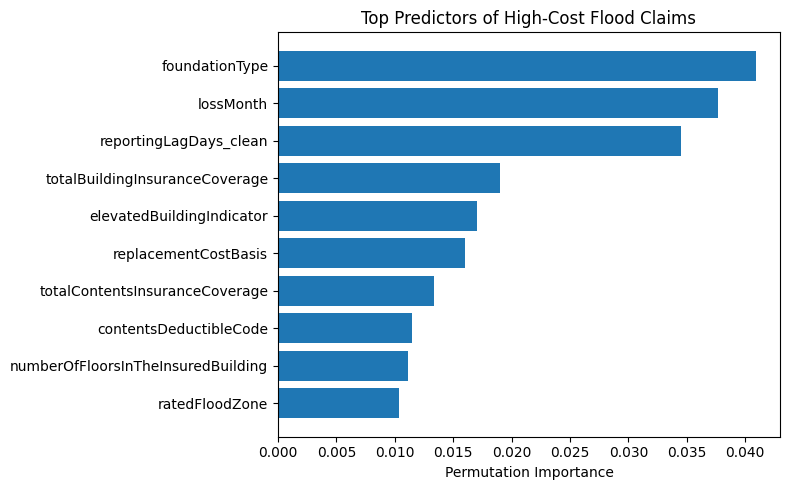

In [45]:
# Check the importance of year of loss.
year_rank = (
    importance_df
    .reset_index()
    .loc[lambda x: x["Feature"] == "yearOfLoss"])

display(year_rank[["Feature", "Importance"]])

# Plot the ten most important predictors.
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))

plt.barh(top_features["Feature"],top_features["Importance"])

plt.title("Top Predictors of High-Cost Flood Claims")
plt.xlabel("Permutation Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()

### Final Feature Importance

The final model relied most on foundation type, loss month, reporting lag, and building insurance coverage. Several property and policy characteristics also contributed to the predictions.

Year of loss had essentially no permutation importance in the final model, which suggests the model was not mainly relying on the general increase in claim costs over time. These results show which variables were useful for prediction, but they do not show the direction of each relationship.

## Technical Model Brief

The goal of this model was to identify flood claims that were likely to result in total payments of 50,000 dollars or more. I limited the modeling period to 2010 through 2024 because a fixed 50,000 dollar threshold was not comparable across the full historical dataset. After removing records with error related or unclear claim status codes, the final modeling population contained 10,040 claims, with about 33% classified as high cost.

I limited the predictors to information that could reasonably be available early in the claim process or already exist on the policy. Payment amounts, damage estimates, recoveries, non-payment reasons, and other outcome related fields were excluded to reduce leakage. Missing numeric values were filled with the training median, categorical values were imputed with the most common category, and categorical variables were one-hot encoded. The data was split chronologically, using 2010 through 2020 for training, 2021 through 2022 for validation, and 2023 through 2024 as the final test period.

I compared a dummy baseline, logistic regression, decision tree, random forest, and gradient boosting model. Logistic regression and the decision tree captured more high-cost claims at the default 0.50 cutoff, but the random forest had the strongest ranking performance. Its initial validation ROC-AUC was 0.733 and PR AUC was 0.584. This showed that the model was ranking higher-cost claims reasonably well even though the default cutoff was too restrictive.

I tuned the random forest using time based cross validation and selected 400 trees, a maximum depth of 10, and a minimum leaf size of 1. The tuned model improved validation ROC AUC to 0.743 and PR AUC to 0.599. Rather than using a fixed probability cutoff, I ranked claims by predicted risk and selected the top 30% as the working priority group. On validation data, this group captured about 51% of all high-cost claims.

The final model was refit on the combined training and validation data and evaluated once on the 2023 through 2024 test period. Test ROC AUC was 0.833 and PR AUC was 0.827. Prioritizing the highest-risk 30% of test claims captured 321 of 643 high-cost claims, or about 50%. For the same review workload, random selection would be expected to capture about 193 high-cost claims, giving the model a capture lift of 1.66. Foundation type, loss month, reporting lag, and building insurance coverage were among the strongest predictors.

There are several limitations to keep in mind. The 30,000 record source sample was built from blocks spread across the full FEMA dataset rather than from a simple random sample. Claim severity also changes over time, which is why the modeling period was restricted to more recent years. Some fields assumed to be available early in the claim process should be confirmed with an actual claims workflow before implementation. The model also misses about half of the high-cost claims when only the top 30% are prioritized, so it should be used for additional resource planning rather than as a rule for excluding claims from normal handling.

A useful next step would be to test the model on a newer period and confirm which predictors are available at first notice of loss. Adding external information such as major flood-event, weather, or catastrophe data may also improve the model's ability to identify unusually severe claims.

## Discussion and Conclusion

This project examined whether information available early in a flood claim could help identify claims that would eventually exceed $50,000. The final random forest model showed that claim and policy information can provide useful separation between higher- and lower-cost claims, even without using final payment or damage information.

The strongest result came from ranking claims by predicted risk rather than treating the model as a simple yes-or-no classifier. In the held-out 2023 through 2024 data, the highest-risk 30% of claims contained about half of all high-cost claims. For the same review workload, this captured about 1.66 times as many high-cost claims as random selection.

The results also show some important limits. Claim severity has changed over time, the modeling sample was created from blocks across the larger FEMA dataset rather than through simple random sampling, and some predictor timing would need to be confirmed in an actual claims operation. The model also does not identify every severe claim, so the results are better suited for prioritizing additional resources than reducing normal claim handling.

Overall, the analysis suggests that an early claim risk ranking could help claims teams focus experienced adjusters or additional review on a smaller group of claims that are more likely to become expensive. A useful next step would be testing the approach on newer claims and confirming which variables are consistently available at first notice of loss.